**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0    Adelie  Torgersen            39.1           18.7              181.0   
1    Adelie  Torgersen            39.5           17.4              186.0   
2    Adelie  Torgersen            40.3           18.0              195.0   
3    Adelie  Torgersen             NaN            NaN                NaN   
4    Adelie  Torgersen            36.7           19.3              193.0   
..      ...        ...             ...            ...                ...   
339  Gentoo     Biscoe             NaN            NaN                NaN   
340  Gentoo     Biscoe            46.8           14.3              215.0   
341  Gentoo     Biscoe            50.4           15.7              222.0   
342  Gentoo     Biscoe            45.2           14.8              212.0   
343  Gentoo     Biscoe            49.9           16.1              213.0   

     body_mass_g     sex  
0         3750.0    Male  
1         3800.0  Female  
2     

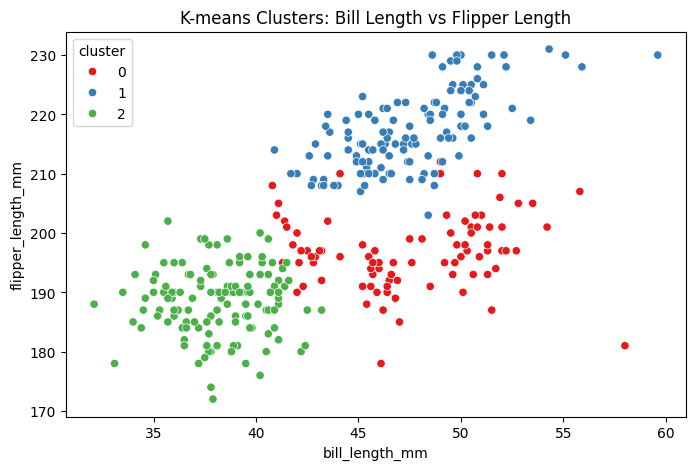

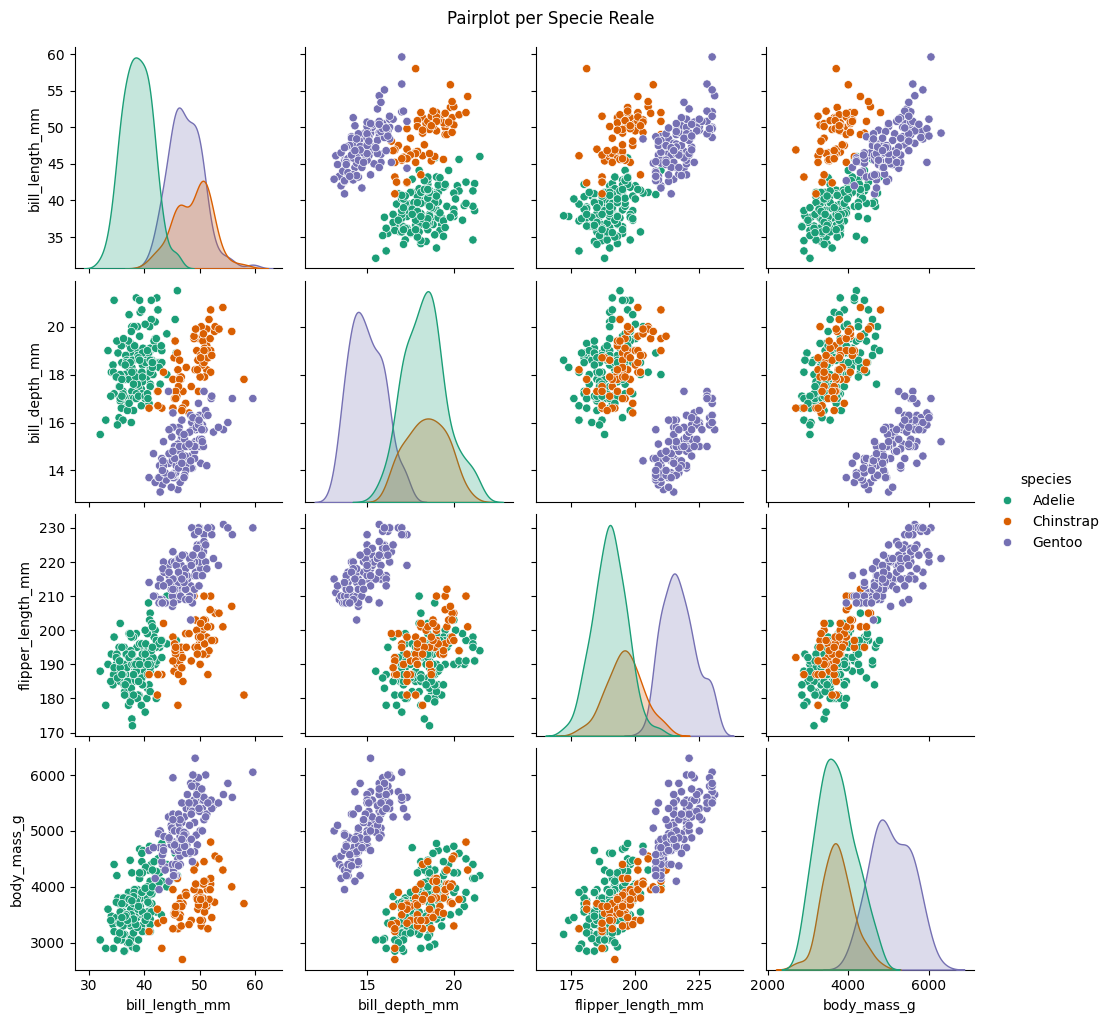

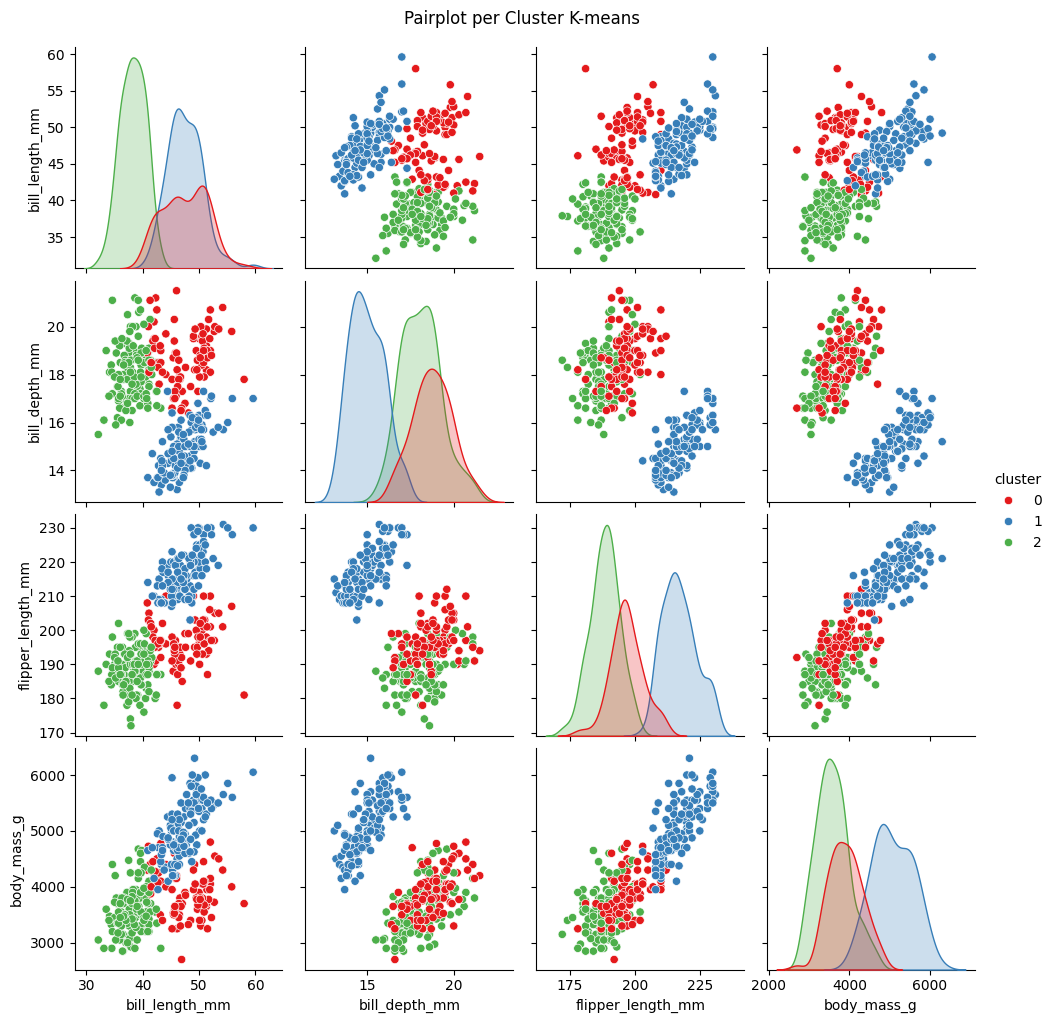

Confusion Matrix:
[[ 24   0 127]
 [ 63   0   5]
 [  0 123   0]]

Adjusted Rand Score: 0.7928


In [5]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']


# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
# Controlla i valori nulli nelle colonne numeriche prima della pulizia
print("Valori nulli per colonna prima del drop:")
print(penguins[num_cols].isna().sum())   # isna().sum() individua i valori NaN (con valori booleani True/False) e ne calcola la somma per ogni colonna
# Rimuoviamo le righe con valori nulli (mantenendo anche la colonna 'species' per i confronti successivi)
penguins_clean = penguins.dropna(subset=num_cols).copy()   # dropna(subset=num_cols) elimina tutte le righe che hanno valori mancanti nelle feature specificate, .copy() crea una copia indipendente in memoria per evitare avvisi di modifica (SettingWithCopyWarning)
# Confermiamo che non ci siano più valori nulli nelle colonne numeriche
print("\nValori nulli dopo il drop:")
print(penguins_clean[num_cols].isna().sum())


# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
scaler = StandardScaler()  # StandardScaler() standardizza le variabili applicando la formula z = (x-mu)/sigma
# Applichiamo fit_transform solo sulle colonne numeriche
scaled_data = scaler.fit_transform(penguins_clean[num_cols])  # fit_transform() calcola contemporaneamente la media e la deviazione standard del dataset (fit) e scala i valori (transform)
# Creiamo un DataFrame con i dati scalati
penguins_scaled_df = pd.DataFrame(
    scaled_data, columns=num_cols, index=penguins_clean.index)


# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
# Inizializziamo ed eseguiamo K-means
kmeans = KMeans(n_clusters=3, random_state=42)  # KMeans(n_clusters=3, random_state=42): imposta il numero di gruppi desiderati, random_state garantisce la riproducibilità dei risultati fissando il seme casuale
kmeans.fit(penguins_scaled_df)
# Salviamo le etichette assegnate dall'algoritmo (0, 1, 2)
kmeans_labels = kmeans.labels_  # kmeans.labels_: array contenente l'id del cluster assegnato a ogni riga


# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)
# Uno scatterplot tra bill_length_mm e flipper_length_mm colorato per cluster. Due pairplot per confrontare le specie reali con i cluster di K-means
# Aggiungiamo i cluster al DataFrame pulito non scalato
penguins_clean['cluster'] = kmeans_labels

# 1. Scatterplot: bill_length_mm vs flipper_length_mm colorato dai cluster
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='cluster',
    palette='Set1',
)
plt.title('K-means Clusters: Bill Length vs Flipper Length')
plt.show()

# 2. Pairplot colorato per specie reale
sns.pairplot(
    data=penguins_clean[num_cols + ['species']], hue='species', palette='Dark2'
)
plt.suptitle('Pairplot per Specie Reale', y=1.02)
plt.show()

# 3. Pairplot colorato per cluster K-means
sns.pairplot(
    data=penguins_clean[num_cols + ['cluster']],
    hue='cluster',  #hue indica la colonna in base alla quale assegnare i diversi colori ai punti nel grafico
    palette='Set1',)  # pairplot: traccia una griglia di scatterplot per tutte le combinazioni a coppie delle feature numeriche, con gli istogrammi di densità lungo la diagonale
plt.suptitle('Pairplot per Cluster K-means', y=1.02)
plt.show()

# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'

# Convertiamo le specie (stringhe) in numeri interi usando LabelEncoder
le = LabelEncoder()
species_encoded = le.fit_transform(penguins_clean['species'])

# Calcoliamo la matrice di confusione tra le specie codificate e i cluster numerici
cm = confusion_matrix(species_encoded, penguins_clean['cluster'])
print("Confusion Matrix:")
print(cm)

# Calcolo dell'Adjusted Rand Score (questo accetta anche stringhe, ma funziona benissimo con i numeri)
ari = adjusted_rand_score(penguins_clean['species'], penguins_clean['cluster'])
print(f"\nAdjusted Rand Score: {ari:.4f}")

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation
#it is written in the text below


# f) YOUR CODE HERE (as a comment or markdown cell): interpretation

1. Does k-means recover the 3 species well?
Yes, it performed very well. K-means is an unsupervised algorithm, so it grouped the penguins without knowing which species they belonged to, looking only at the shape and dimensions of their physical characteristics. We verify this using the Adjusted Rand Score, which yields a score of 0.7928 (this ranges from 1.0, representing a perfect split, to 0.0, indicating a poor one). The confusion matrix reveals that almost all specimens of a given species end up in a single numerical cluster assigned by the algorithm.

2. Which species seem to get confused with each other, if any.
The Adélie and Chinstrap species are the ones most frequently confused, whereas the Gentoo is isolated almost perfectly.

Anatomically, Gentoo penguins are quite distinct; they are heavier (body_mass_g) and have significantly longer flippers (flipper_length_mm). In the feature space, they form a "cloud" of points clearly separated from the other two species, which is why K-means assigns them to a cluster that is virtually 100% pure.

In contrast, the Adélie and Chinstrap species overlap because they are nearly identical in size and weight. Their primary biological difference lies in their beak proportions (the Chinstrap has a longer beak relative to its depth, while the Adélie has a shorter, stockier beak). K-means employs spherical Euclidean distances based on all four variables. For the algorithm, the overall similarity in weight and flipper length outweighs subtle differences in beak shape, causing some individuals to end up in the wrong cluster.

3. Did normalizing the features change the result compared to using the raw values?
Yes, it did. In fact, clustering performance suffers without normalization. If the units of measurement were not standardized, body mass (`body_mass_g`) would range roughly between 2,700 and 6,300 grams, with differences between penguins in the order of hundreds or thousands. Bill measurements (`bill_length_mm` and `bill_depth_mm`), however, vary only between 13 and 60 millimeters, with differences of just a few millimeters or fractions thereof. The K-means algorithm measures the Euclidean distance between points by calculating the sum of the squared differences for each variable. If raw data is used, a 500 g difference in mass carries far more weight (500² = 250000) than a 5 mm difference in bill size (5² = 25). Consequently, without `StandardScaler`, K-means almost entirely ignores bill measurements and groups the penguins solely based on their weight (light, medium, or heavy).


---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Ci sono valori mancanti in X? False
5.656854249492381
5.656854249492381


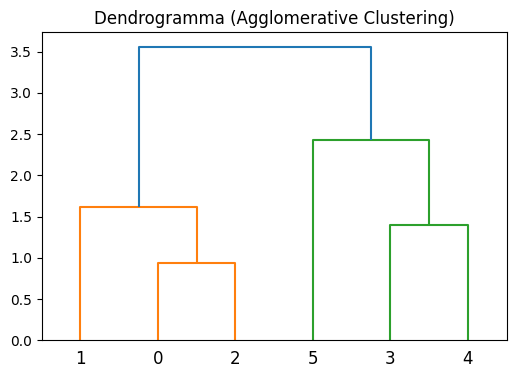

[1 1 1 0 0 0]
[0 0 0 1 1 1]


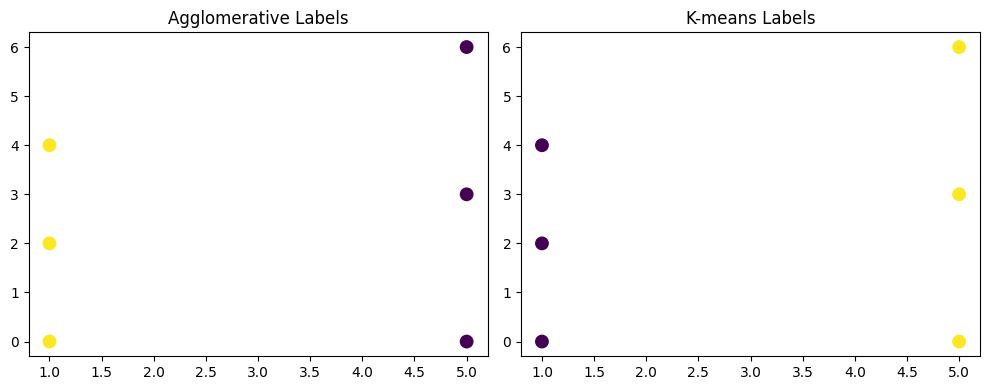

{np.int64(1): 3, np.int64(0): 3}
{np.int32(0): 3, np.int32(1): 3}


In [32]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
# np.isnan(X) restituisce una matrice booleana (True per NaN, False per valori validi)
# .any() verifica se esiste almeno un valore True in tutta la matrice
print("Ci sono valori mancanti in X?", np.isnan(X).any()) #np.isnan(X) scansiona tutti gli elementi dell'array per trovare eventuali NaN, .any() restituisce False perché non ci sono dati mancanti


# b) YOUR CODE HERE: normalize X with StandardScaler
# Inizializza lo scaler che calcola media e deviazione standard
scaler = StandardScaler()

# fit_transform centra le colonne su media 0 e scala a varianza unitaria (1)
X_scaled = scaler.fit_transform(X)


# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
    # Inizializza la somma dei quadrati delle differenze a zero
    sum_sq = 0
    # Scorre le coordinate corrispondenti di entrambi i punti usando zip
    for c1, c2 in zip(p1, p2):  # zip(p1, p2) accoppia ogni coordinata di p1 con la rispettiva di p2
        # Aggiunge il quadrato della differenza tra le coordinate
        sum_sq += (c1 - c2) ** 2  # (c1 - c2) ** 2 calcola la distanza al quadrato su ogni asse
    # Calcola e restituisce la radice quadrata elevando a 0.5
    return sum_sq ** 0.5  # sum_sq ** 0.5 applica la radice quadrata della formula euclidea senza librerie esterne. Entrambe le stampe di test daranno lo stesso identico risultato (circa 5.6568)

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))


# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
# Crea l'oggetto per il clustering gerarchico agglomerativo specificando 2 cluster
agglo = AgglomerativeClustering(n_clusters=2)  # AgglomerativeClustering(n_clusters=2) imposta il clustering gerarchico per fermarsi a 2 gruppi

# Addestra il modello sui dati normalizzati ed estrae le etichette dei gruppi
agglo_labels = agglo.fit_predict(X_scaled)

# Calcola la matrice di collegamento tra i punti con il metodo 'ward'
linkage_matrix = linkage(X_scaled, method='ward')  # linkage(X_scaled, method='ward') costruisce l'albero gerarchico unendo i punti che minimizzano la varianza interna

# Crea una nuova figura per il grafico
plt.figure(figsize=(6, 4))

# Genera e disegna il dendrogramma a partire dalla matrice di linkage
dendrogram(linkage_matrix) # dendrogram() visualizza l'albero con i rami e le distanze di fusione

# Aggiunge il titolo al grafico
plt.title("Dendrogramma (Agglomerative Clustering)")

# Mostra il grafico a schermo
plt.show()


# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
# Inizializza l'algoritmo K-means con 2 cluster e un random_state per riproducibilità
kmeans = KMeans(n_clusters=2, random_state=42)  # KMeans(n_clusters=2) imposta l'algoritmo per cercare due centroidi

# Addestra il modello K-means sui dati normalizzati
kmeans.fit(X_scaled)

# Assegna le etichette trovate (0 e 1) alla variabile kmeans_labels
kmeans_labels = kmeans.labels_  # kmeans.labels_ contiene il vettore delle assegnazioni per ciascuna riga del dataset


# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
print(agglo_labels)
print(kmeans_labels)
# Crea una figura con 1 riga e 2 colonne di sotto-grafici affiancati
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Disegna i punti originali sul primo asse colorandoli con le etichette di Agglomerative
axes[0].scatter(X[:, 0], X[:, 1], c=agglo_labels, cmap='viridis', s=80)  # c=agglo_labels colora i punti in base al cluster di appartenenza
# Imposta il titolo del primo riquadro
axes[0].set_title("Agglomerative Labels")

# Disegna i punti originali sul secondo asse colorandoli con le etichette di K-means
axes[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', s=80)  # c=kmeans_labels colora i punti in base al cluster di appartenenza
# Imposta il titolo del secondo riquadro
axes[1].set_title("K-means Labels")

# Regola la spaziatura automatica tra i grafici
plt.tight_layout()

# Mostra entrambi i grafici a schermo
plt.show()


# g) YOUR CODE HERE: cluster_sizes function using a dictionary
def cluster_sizes(labels):
    # Inizializza un dizionario vuoto per memorizzare le frequenze
    counts = {}
    # Scorre ciascuna etichetta presente nel vettore
    for label in labels:
        # Se la chiave è già presente nel dizionario, incrementa il conteggio di 1
        if label in counts:
            counts[label] += 1
        # Se l'etichetta non è ancora presente, la inserisce impostandola a 1
        else:
            counts[label] = 1
    # Restituisce il dizionario finale contenente le dimensioni dei cluster
    return counts
# confermando che ciascun cluster contiene esattamente 3 campioni

print(cluster_sizes(agglo_labels))
print(cluster_sizes(kmeans_labels))


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Valori nulli prima del dropna:
carat    0
depth    0
table    0
price    0
dtype: int64

Valori nulli dopo il dropna:
carat    0
depth    0
table    0
price    0
dtype: int64


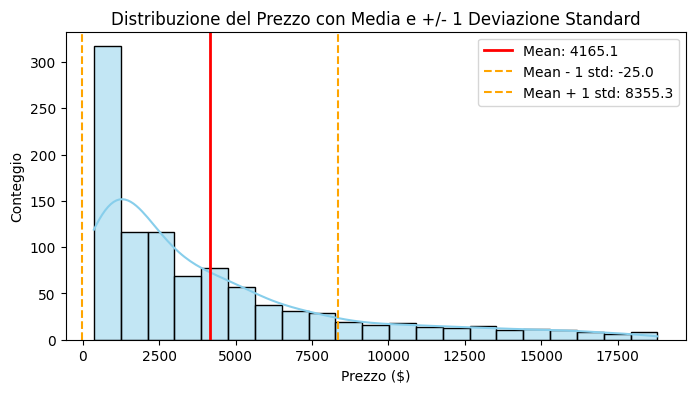

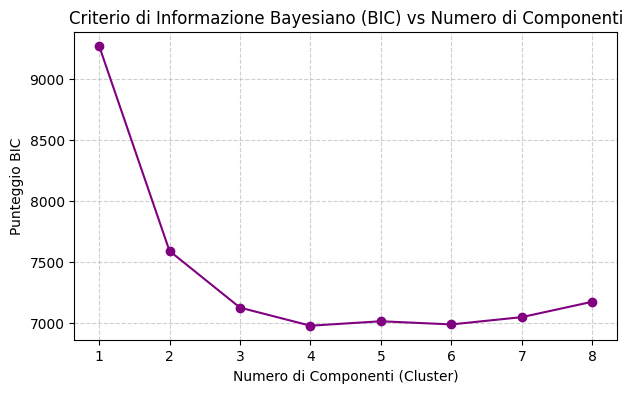

Numero ottimale di componenti (BIC minimo): 4


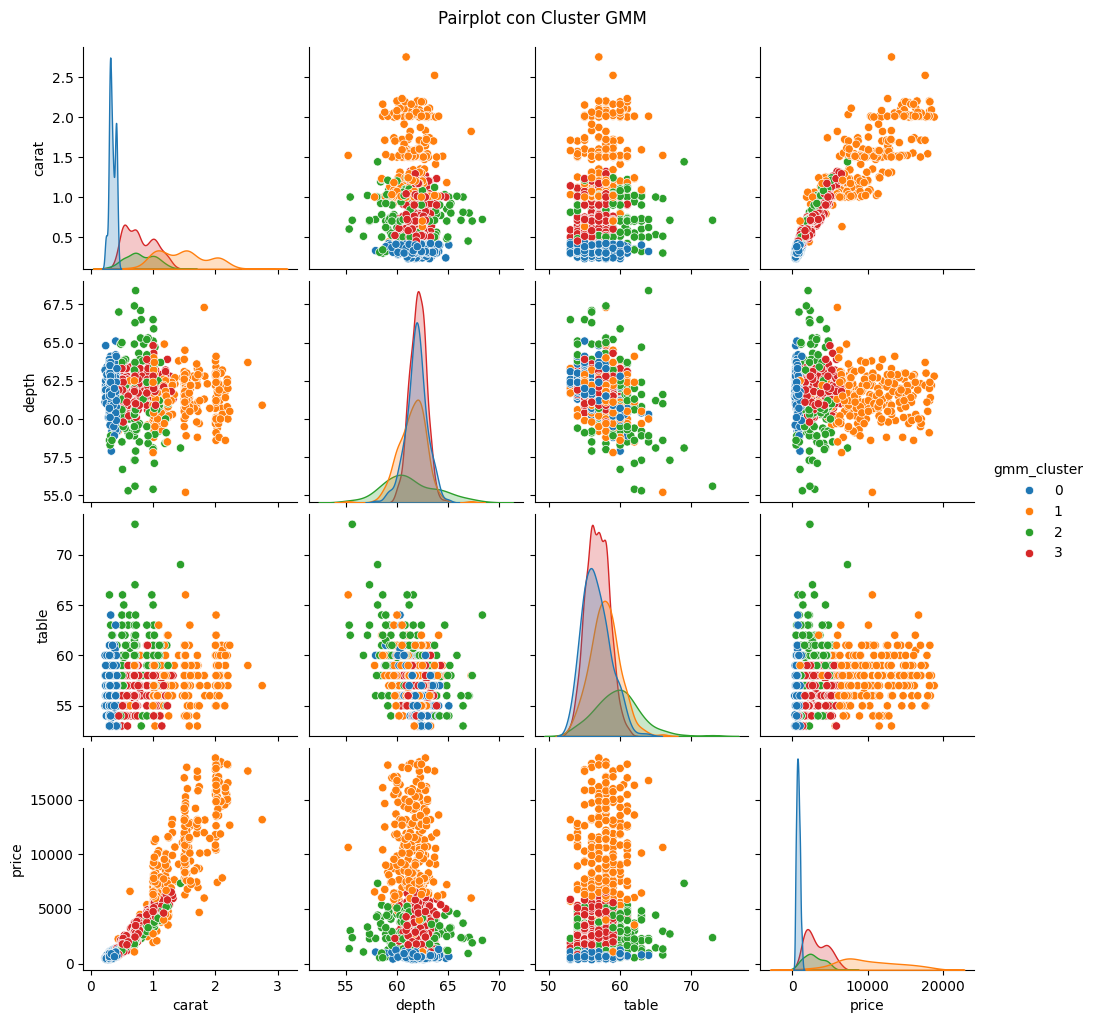

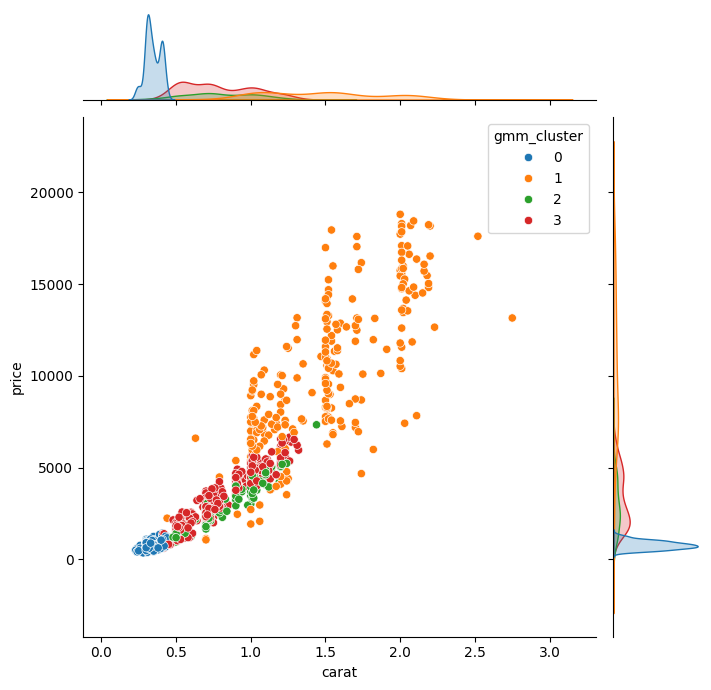

In [38]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
# Selezione delle 4 colonne numeriche richieste
cols = ['carat', 'depth', 'table', 'price']
diamonds_num = diamonds[cols].copy()

# Controllo dei valori mancanti (NaN) che ci sono per colonna
print("Valori nulli prima del dropna:")
print(diamonds_num.isna().sum())

# 3. Rimozione delle righe con valori nulli
diamonds_num = diamonds_num.dropna()

# 4. Conferma che il dataframe sia pulito (nessun NaN residuo)
print("\nValori nulli dopo il dropna:")
print(diamonds_num.isna().sum())


# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
# Calcoliamo la media e la deviazione standard della colonna price
mean_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()

# Creazione della figura per il grafico
plt.figure(figsize=(8, 4))

# Istogramma con la stima di densità (kde=True)
sns.histplot(diamonds_num['price'], kde=True, color='skyblue')

# Linea verticale per la media (linea rossa continua)
plt.axvline(mean_price, color='red', linestyle='-', linewidth=2, label=f'Mean: {mean_price:.1f}')

# Linee verticali per mean - std e mean + std (linee tratteggiate)
plt.axvline(
    mean_price - std_price,
    color='orange',
    linestyle='--',
    linewidth=1.5,
    label=f'Mean - 1 std: {mean_price - std_price:.1f}',)
plt.axvline(
    mean_price + std_price,
    color='orange',
    linestyle='--',
    linewidth=1.5,
    label=f'Mean + 1 std: {mean_price + std_price:.1f}',)

# Aggiungiamo titolo, legenda ed etichette
plt.title('Distribuzione del Prezzo con Media e +/- 1 Deviazione Standard')
plt.xlabel('Prezzo ($)')
plt.ylabel('Conteggio')
plt.legend()
plt.show()


# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
# Inizializzazione e standardizzazione
scaler = StandardScaler()

# Calcolo media/std e trasformazione dei dati portandoli a media 0 e deviazione standard 1
diamonds_scaled = scaler.fit_transform(diamonds_num)


# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)
# Cicliamo sul range di componenti da 1 a 8
for n in n_components_range:
  # Inizializzazione del Gaussian Mixture Model con n componenti
  gmm = mixture.GaussianMixture(n_components=n, random_state=42)
  # Addestramento del modello sui dati normalizzati
  gmm.fit(diamonds_scaled)
  # Calcolo del BIC e il suo salvataggio nella lista bic
  bic.append(gmm.bic(diamonds_scaled))

# Grafico dell'andamento del BIC
plt.figure(figsize=(7, 4))
plt.plot(n_components_range, bic, marker='o', linestyle='-', color='purple')
plt.title('Criterio di Informazione Bayesiano (BIC) vs Numero di Componenti')
plt.xlabel('Numero di Componenti (Cluster)')
plt.ylabel('Punteggio BIC')
plt.xticks(n_components_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
# Ricerca del numero di componenti che corrisponde al valore minimo di BIC
best_n = n_components_range[np.argmin(bic)] #np.argmin(bic) individua l'indice del punteggio più basso. Si allena quindi il GMM definitivo con tale iperparametro per ottenere i raggruppamenti (gmm_labels)
print(f"Numero ottimale di componenti (BIC minimo): {best_n}")

# Inizializzazione e addestramento del modello definitivo con best_n
final_gmm = mixture.GaussianMixture(n_components=best_n, random_state=42)
final_gmm.fit(diamonds_scaled)

# Predizione dell'assegnazione dei cluster per ciascun punto
gmm_labels = final_gmm.predict(diamonds_scaled)

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
# Aggiunta delle etichette predette come nuova colonna al dataframe originale non scalato
diamonds_num['gmm_cluster'] = gmm_labels

# 1. Pairplot di tutte e quattro le variabili colorate in base al cluster GMM
sns.pairplot(
    data=diamonds_num,
    vars=['carat', 'depth', 'table', 'price'],
    hue='gmm_cluster',
    palette='tab10',)
plt.suptitle('Pairplot con Cluster GMM', y=1.02)
plt.show()

# 2. Jointplot per osservare da vicino la relazione chiave tra carat e price
sns.jointplot(
    data=diamonds_num,
    x='carat',
    y='price',
    hue='gmm_cluster',
    palette='tab10',
    height=7,)
plt.show()

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation
# it is written in the text below


g) YOUR CODE HERE (as a comment or markdown cell): interpretationIn
1. Does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot?
Yes. In the pairplot and jointplot, one can see how the BIC components continuously segment the range of diamonds—from very small, inexpensive ones (low carat, low price) to rare, large, high-value stones—while also capturing variations in cut proportions (table/depth).

2. Would you have guessed the same number just by eye?
It's very hard. To the naked eye, when looking at a scatterplot, the data do not appear as distinct, isolated spheres or blobs (like in the penguin dataset), but rather as a dense, continuous distribution rising towards the upper right. Visually, one might be inclined to hypothesize two or three general groups ("cheap," "mid-range," "expensive"), whereas the mathematical BIC criterion indicates that multiple overlapping Gaussian components are required to accurately model the curvature.


3. Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?
Yes. If applied to unnormalized data, the enormous variance of *price* dominates the likelihood calculation. The model ends up ignoring *depth* and *table*, altering the BIC curve and leading to a different number of optimal components—components focused solely on horizontally slicing the price histogram rather than identifying the true joint distribution of the features.